# Домашнее задание 9

Загрузка `events.json` в pandas и распределение событий по полю `signature`.

In [1]:
!pip install -q pandas matplotlib seaborn


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\Andrei\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


## Этап 1–2. Загрузка и анализ

In [2]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("events.json")

with DATA_PATH.open(encoding="utf-8") as f:
    raw = json.load(f)

df = pd.DataFrame(raw["events"])
df["timestamp"] = pd.to_datetime(df["timestamp"])

print("rows:", len(df))
print("columns:", list(df.columns))
df.head()

rows: 100
columns: ['timestamp', 'signature']


,timestamp,signature
0,2023-08-21 08:00:00,MALWARE-CNC Win.Trojan.Jadtre variant outbound...
1,2023-08-21 09:00:00,EXPLOIT Remote Windows Win32k elevation of pri...
2,2023-08-21 10:00:00,EXPLOIT Java JRE to Oracle WebLogic RCE
3,2023-08-21 11:00:00,NETBIOS DCERPC NCACN-IP-TCP interfaces BO
4,2023-08-21 12:00:00,MALWARE-CNC User-Agent known malicious connect...


In [3]:
signature_counts = (
    df["signature"]
    .value_counts()
    .rename_axis("signature")
    .reset_index(name="count")
)

print("unique signatures:", signature_counts.shape[0])
signature_counts

unique signatures: 9


,signature,count
0,MALWARE-CNC Win.Trojan.Jadtre variant outbound...,12
1,EXPLOIT Remote Windows Win32k elevation of pri...,11
2,EXPLOIT Java JRE to Oracle WebLogic RCE,11
3,NETBIOS DCERPC NCACN-IP-TCP interfaces BO,11
4,MALWARE-CNC User-Agent known malicious connect...,11
5,INDICATOR-COMPROMISE Suspicious inbound to myS...,11
6,EXPLOIT Multiple IIS 6.0 attempt,11
7,EXPLOIT Oracle 9i TNS Listener BO,11
8,NETBIOS SMB-DS srvsvc NetrPathCanonicalize BO,11


## Этап 3. Визуализация

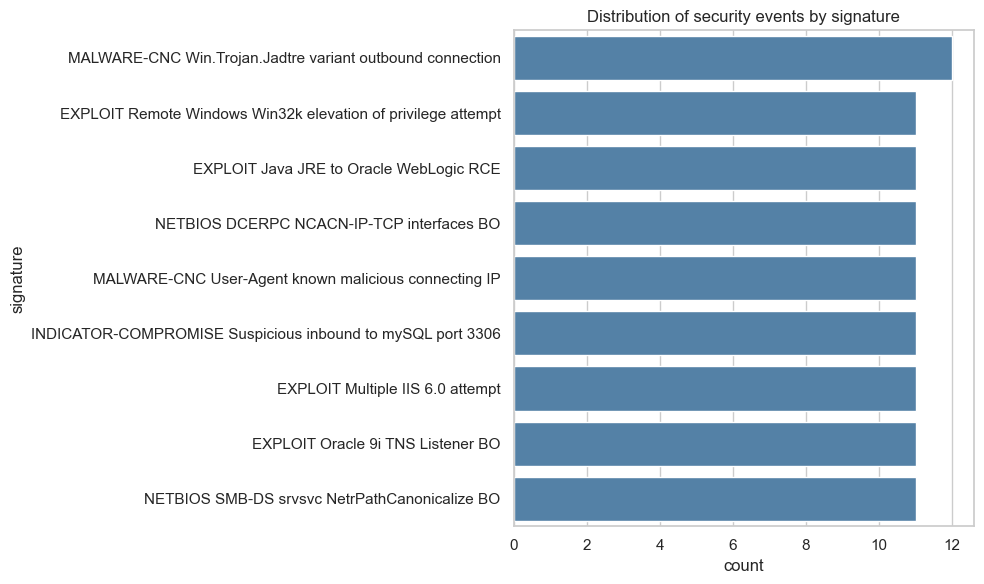

In [4]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=signature_counts,
    y="signature",
    x="count",
    color="steelblue",
)
ax.set_title("Distribution of security events by signature")
ax.set_xlabel("count")
ax.set_ylabel("signature")
plt.tight_layout()
plt.show()